
多因子选股项目 - 数据探索 Notebook

用途：直接读取项目已处理好的 parquet 文件，做探索和可视化
位置：放在项目根目录下运行，或改 PROJECT_ROOT 指向项目根


In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
%matplotlib inline

In [2]:
# 中文字体（可选，Windows/Mac 可能不同）
plt.rcParams["font.sans-serif"] = ["SimHei", "Arial Unicode MS", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False

In [3]:
# 显示设置
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda x: f"{x:.4f}")


0. 定位项目根目录 & 数据路径


In [4]:
# 方式 1：假设 notebook 在项目根目录
PROJECT_ROOT = Path.cwd()

方式 2：如果 notebook 在 notebooks/ 下，取消下面这行的注释
PROJECT_ROOT = Path.cwd().parent

In [5]:
RAW_DIR = PROJECT_ROOT / "data" / "raw"
PROC_DIR = PROJECT_ROOT / "data" / "processed"
OUT_DIR = PROJECT_ROOT / "outputs" / "results"

In [6]:
print(f"项目根目录: {PROJECT_ROOT}")
print(f"raw 目录存在: {RAW_DIR.exists()}")
print(f"processed 目录存在: {PROC_DIR.exists()}")

项目根目录: D:\Users\lenovo\PycharmProjects(D)\Quantitative Trading\LightGBM
raw 目录存在: True
processed 目录存在: True


In [7]:
# 列出所有 parquet 文件
for d, name in [(RAW_DIR, "raw"), (PROC_DIR, "processed"), (OUT_DIR, "outputs")]:
    if d.exists():
        files = sorted(d.glob("*.parquet"))
        print(f"\n{name} 目录下的 parquet 文件 ({len(files)} 个):")
        for f in files:
            size_mb = f.stat().st_size / 10242
            print(f"  {f.name:45s} {size_mb:8.2f} MB")


raw 目录下的 parquet 文件 (6 个):
  constituents.parquet                              0.01 MB
  daily_prices.parquet                             18.42 MB
  financial_data.parquet                            0.50 MB
  index_daily.parquet                               0.15 MB
  industry_classification.parquet                   0.01 MB
  valuation.parquet                                 9.93 MB

processed 目录下的 parquet 文件 (7 个):
  factors.parquet                                  50.98 MB
  factors_processed.parquet                        78.30 MB
  financial_data.parquet                            0.50 MB
  index_data.parquet                                0.15 MB
  industry.parquet                                  0.01 MB
  labels.parquet                                    6.13 MB
  market_data.parquet                              28.27 MB

outputs 目录下的 parquet 文件 (5 个):
  backtest_lightgbm.parquet                         0.01 MB
  backtest_linear_regression.parquet                0.01 MB
  back


1. 原始数据：成分股


In [8]:
def load_if_exists(path, name=""):
    """文件存在就加载，否则返回 None"""
    if path.exists():
        df = pd.read_parquet(path)
        print(f"[OK] 加载 {name or path.name}: shape={df.shape}")
        return df
    else:
        print(f"[MISS] 文件不存在: {path}")
        return None

In [9]:
constituents = load_if_exists(RAW_DIR / "constituents.parquet", "成分股")

[OK] 加载 成分股: shape=(300, 3)


In [12]:
if constituents is not None:
    print("\n前 10 只成分股:")
    print(constituents.head(10))
    print(f"\n列: {constituents.columns.tolist()}")
    print(f"股票数: {len(constituents)}")


前 10 只成分股:
     code  name        纳入日期
0  600118  中国卫星  2026-06-15
1  002532  天山铝业  2026-06-15
2  000988  华工科技  2026-06-15
3  000657  中钨高新  2026-06-15
4  301308   江波龙  2026-06-15
5  688072  拓荆科技  2026-06-15
6  002202  金风科技  2026-06-15
7  301165  锐捷网络  2026-06-15
8  002558  巨人网络  2026-06-15
9  688183  生益电子  2026-06-15

列: ['code', 'name', '纳入日期']
股票数: 300



2. 原始行情数据 daily_prices.parquet


In [13]:
daily_prices = load_if_exists(RAW_DIR / "daily_prices.parquet", "日频行情")

[OK] 加载 日频行情: shape=(373806, 8)



索引层级: ['date', 'code']
列: ['open', 'high', 'low', 'close', 'pre_close', 'volume', 'amount', 'pct_change']

日期范围: 2018-01-02 00:00:00 ~ 2023-12-29 00:00:00
股票数: 285

前 5 行:
                       open      high       low     close  pre_close       volume       amount  pct_change
date       code                                                                                           
2018-01-02 000001 1419.2251 1480.8844 1416.0359 1456.4333    13.3000 2081592.5500 2856543.8220      3.0100
           000002 4318.0850 4529.5270 4318.0850 4470.4880    31.0600  683433.5000 2218502.7660      4.8300
           000063  575.9098  577.8042  549.0719  564.0695    36.3600  899607.4200 3195105.2410     -1.7300
           000157  289.1165  298.2123  289.1165  295.6135     4.4700  663218.5800  301680.7470      1.7900
           000166    7.5073    7.5492    7.4513    7.5212     5.3700  176648.7800   94793.2790      0.1900

描述性统计:
             open        high         low       close   pre_close     

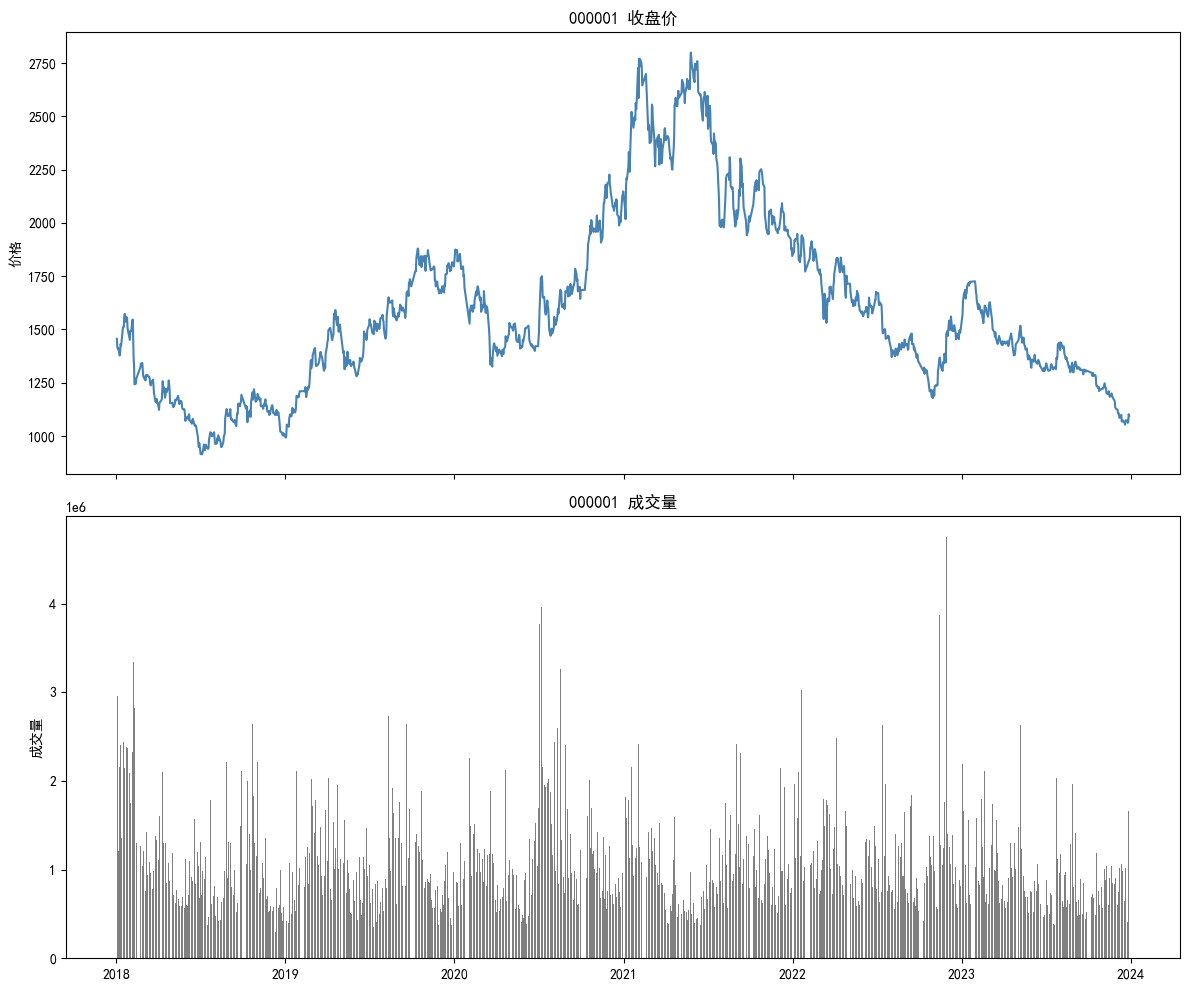


2018-06-04 00:00:00 横截面（前 5 行）:
            open      high       low     close  pre_close      volume       amount  pct_change
code                                                                                          
000001 1087.5411 1096.0458 1079.0364 1091.7934    10.1900 593038.3500  608291.9780      0.7900
000002 3610.9900 3759.2740 3608.2440 3748.2900    26.0000 789190.7700 2138820.8370      5.0000
000157  272.8740  274.8231  270.2752  273.5237     4.2100 203390.2800   85486.9920      0.0000
000166    6.5147    6.5287    6.4308    6.4588     4.6600 133097.3000   61641.8530     -0.8600
000301   15.1179   15.8021   15.0517   15.6697     6.8300 291886.6700  205540.2700      3.9500
当天股票数: 221


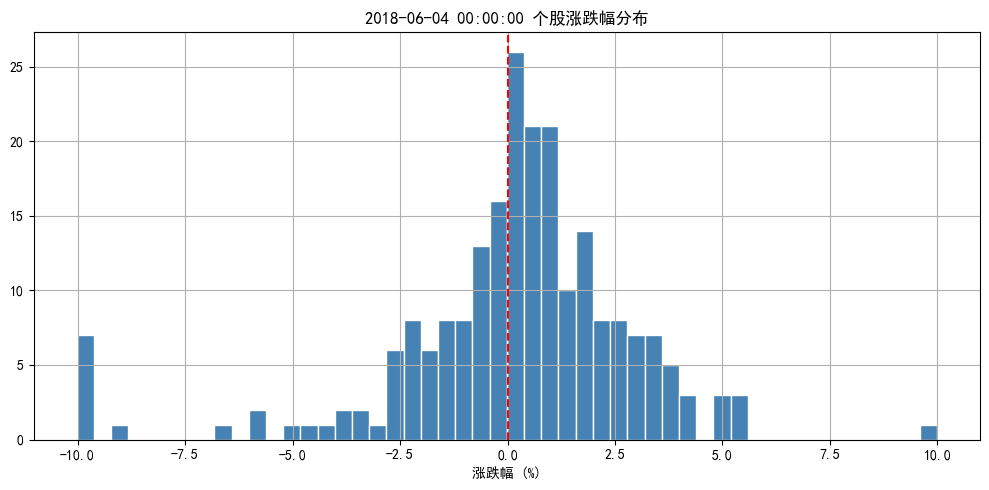

In [22]:
if daily_prices is not None:
    print(f"\n索引层级: {daily_prices.index.names}")
    print(f"列: {daily_prices.columns.tolist()}")
    print(f"\n日期范围: {daily_prices.index.get_level_values('date').min()} ~ "
          f"{daily_prices.index.get_level_values('date').max()}")
    print(f"股票数: {daily_prices.index.get_level_values('code').nunique()}")
    print(f"\n前 5 行:")
    print(daily_prices.head())
    print(f"\n描述性统计:")
    print(daily_prices.describe())

    # ----- 2.1 取一只股票看时间序列 -----
    sample_code = daily_prices.index.get_level_values("code").unique()[0]
    one_stock = daily_prices.xs(sample_code, level="code")
    print(f"\n股票 {sample_code} 的前 5 行:")
    print(one_stock.head())

    # 画收盘价
    fig, axes = plt.subplots(2, 1, figsize=(14, 10), sharex=True)
    axes[0].plot(one_stock.index, one_stock["close"], color="steelblue")
    axes[0].set_title(f"{sample_code} 收盘价")
    axes[0].set_ylabel("价格")

    if "volume" in one_stock.columns:
        axes[1].bar(one_stock.index, one_stock["volume"], color="gray", width=1)
        axes[1].set_title(f"{sample_code} 成交量")
        axes[1].set_ylabel("成交量")

    plt.tight_layout()
    plt.savefig(PROJECT_ROOT / "notebooks" / "sample_stock.png", dpi=100, bbox_inches="tight")
    plt.show()

    # ----- 2.2 取一天看横截面 -----
    sample_date = daily_prices.index.get_level_values("date").unique()[100]
    one_day = daily_prices.xs(sample_date, level="date")
    print(f"\n{sample_date} 横截面（前 5 行）:")
    print(one_day.head())
    print(f"当天股票数: {len(one_day)}")

    # 画当天收益率分布
    if "pct_change" in one_day.columns:
        fig, ax = plt.subplots(figsize=(10, 5))
        one_day["pct_change"].hist(bins=50, ax=ax, color="steelblue", edgecolor="white")
        ax.axvline(0, color="red", linestyle="--")
        ax.set_title(f"{sample_date} 个股涨跌幅分布")
        ax.set_xlabel("涨跌幅 (%)")
        plt.tight_layout()
        plt.savefig(PROJECT_ROOT / "notebooks" / "cross_section_return.png", dpi=100, bbox_inches="tight")
        plt.show()


3. 估值数据 valuation.parquet


In [23]:
valuation = load_if_exists(RAW_DIR / "valuation.parquet", "估值数据")

[OK] 加载 估值数据: shape=(373807, 6)



列: ['pe_ttm', 'pb', 'ps_ttm', 'total_mv', 'dv_ratio', 'turnover_rate']

前 5 行:
                   pe_ttm     pb  ps_ttm      total_mv  dv_ratio  turnover_rate
date       code                                                                
2018-01-02 000001 10.2129 1.1871  2.2280 23523463.5714    1.1533         1.2304
           000002 15.0699 3.0886  1.4944 35943478.9153    2.4263         0.7039
           000063     NaN 3.7331  1.4099 14980416.4950    0.0000         2.6212
           000157 30.8127 0.9405  1.4913  3546291.8741    3.2099         1.0653
           000166 20.9780 1.9798  7.6002 10790453.8763    1.8587         0.2384

缺失率:
pe_ttm          0.0444
pb              0.0011
ps_ttm          0.0000
total_mv        0.0000
dv_ratio        0.0522
turnover_rate   0.0000
dtype: float64


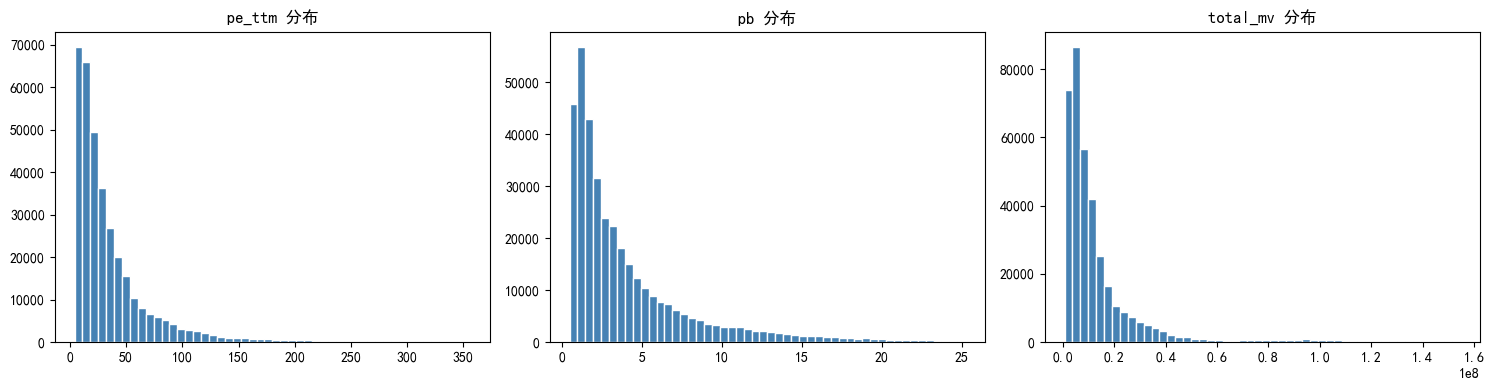

In [24]:
if valuation is not None:
    print(f"\n列: {valuation.columns.tolist()}")
    print(f"\n前 5 行:")
    print(valuation.head())
    print(f"\n缺失率:")
    print(valuation.isna().mean())

    # PE 分布
    if "pe_ttm" in valuation.columns:
        fig, axes = plt.subplots(1, 3, figsize=(5, 4))
        for ax, col in zip(axes, ["pe_ttm", "pb", "total_mv"]):
            if col in valuation.columns:
                data = valuation[col].dropna()
                data = data[(data > data.quantile(0.01)) & (data < data.quantile(0.99))]
                ax.hist(data, bins=50, color="steelblue", edgecolor="white")
                ax.set_title(f"{col} 分布")
        plt.tight_layout()
        plt.savefig(PROJECT_ROOT / "notebooks" / "valuation_dist.png", dpi=100, bbox_inches="tight")
        plt.show()


4. 指数数据 index_daily.parquet


In [25]:
index_daily = load_if_exists(RAW_DIR / "index_daily.parquet", "指数行情")

[OK] 加载 指数行情: shape=(1726, 10)



列: ['ts_code', 'close', 'open', 'high', 'low', 'pre_close', 'change', 'pct_chg', 'vol', 'amount']
日期范围: 2016-11-28 00:00:00 ~ 2023-12-29 00:00:00


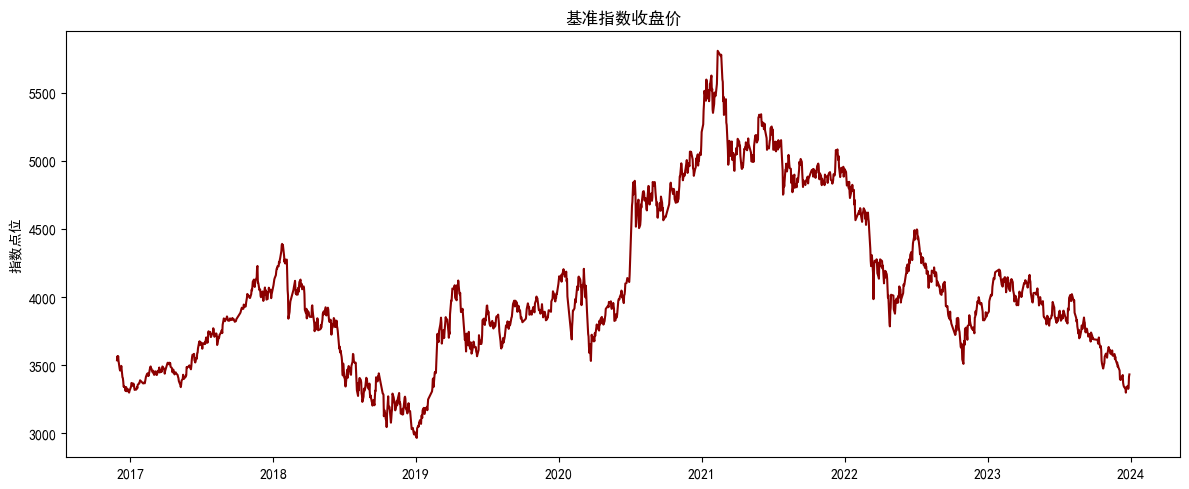

In [26]:
if index_daily is not None:
    print(f"\n列: {index_daily.columns.tolist()}")
    print(f"日期范围: {index_daily.index.min()} ~ {index_daily.index.max()}")

    fig, ax = plt.subplots(figsize=(14, 5))
    ax.plot(index_daily.index, index_daily["close"], color="darkred")
    ax.set_title("基准指数收盘价")
    ax.set_ylabel("指数点位")
    plt.tight_layout()
    plt.savefig(PROJECT_ROOT / "notebooks" / "index_close.png", dpi=100, bbox_inches="tight")
    plt.show()


5. 行业分类数据探索 industry.parquet


In [37]:
industry = load_if_exists(PROC_DIR / "industry.parquet", "行业分类")

[OK] 加载 行业分类: shape=(288, 2)



列: ['code', 'industry']
形状: (288, 2)

前 10 行:
      code industry
0   002311     农林牧渔
1   002714     农林牧渔
2   300498     农林牧渔
3   300999     农林牧渔
4   600438     农林牧渔
5   600893     农林牧渔
6   000301     基础化工
7   000408     基础化工
9   000792     基础化工
12  002001     基础化工

行业数量: 28 个

各行业股票数（按数量排序）:
industry
电子      43
非银金融    25
银行      23
有色金属    19
基础化工    18
交通运输    17
电力设备    16
医药生物    15
计算机     14
食品饮料    12
机械设备    11
汽车      11
建筑装饰     9
公用事业     9
通信       7
农林牧渔     6
家用电器     5
国防军工     5
房地产      4
煤炭       4
钢铁       4
商贸零售     3
传媒       2
石油石化     2
建筑材料     1
综合       1
纺织服饰     1
社会服务     1
Name: count, dtype: int64


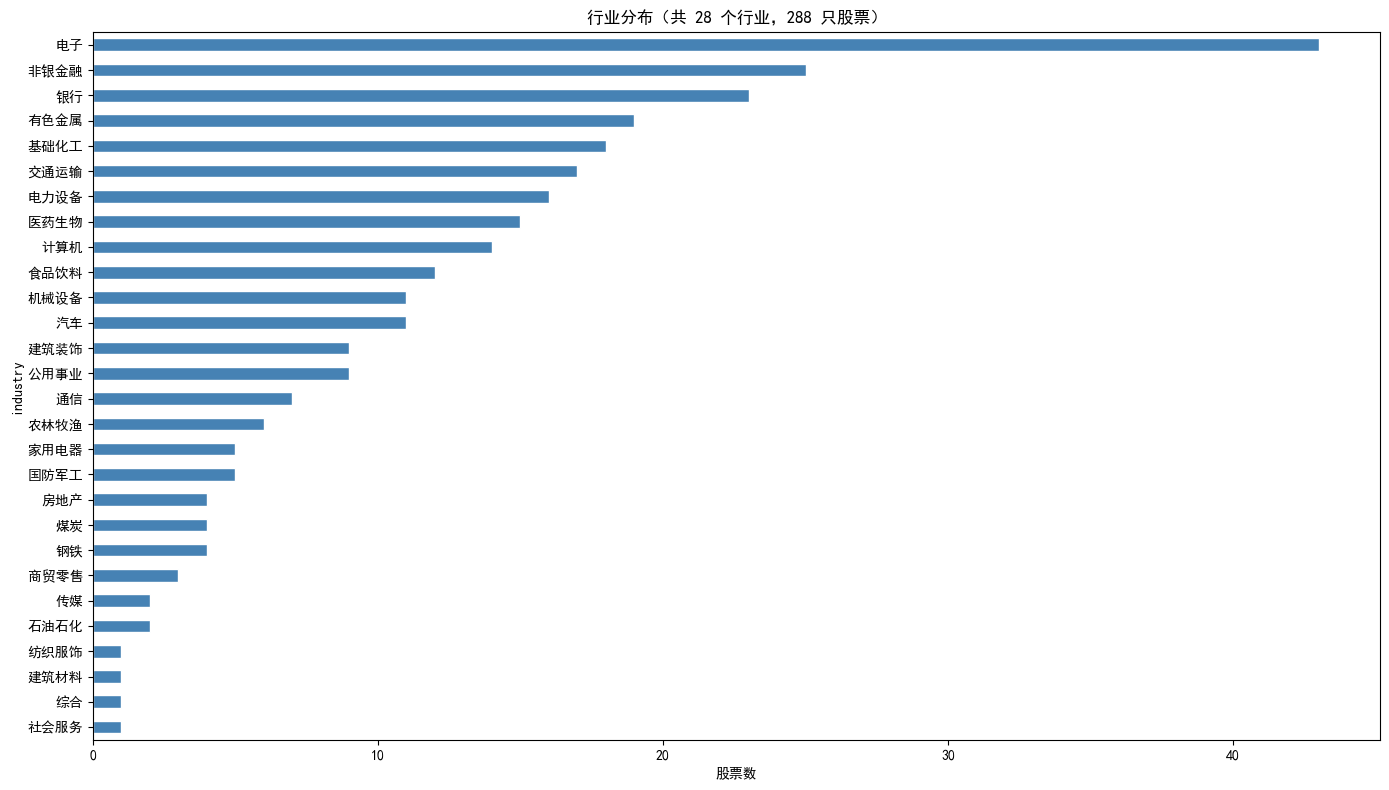

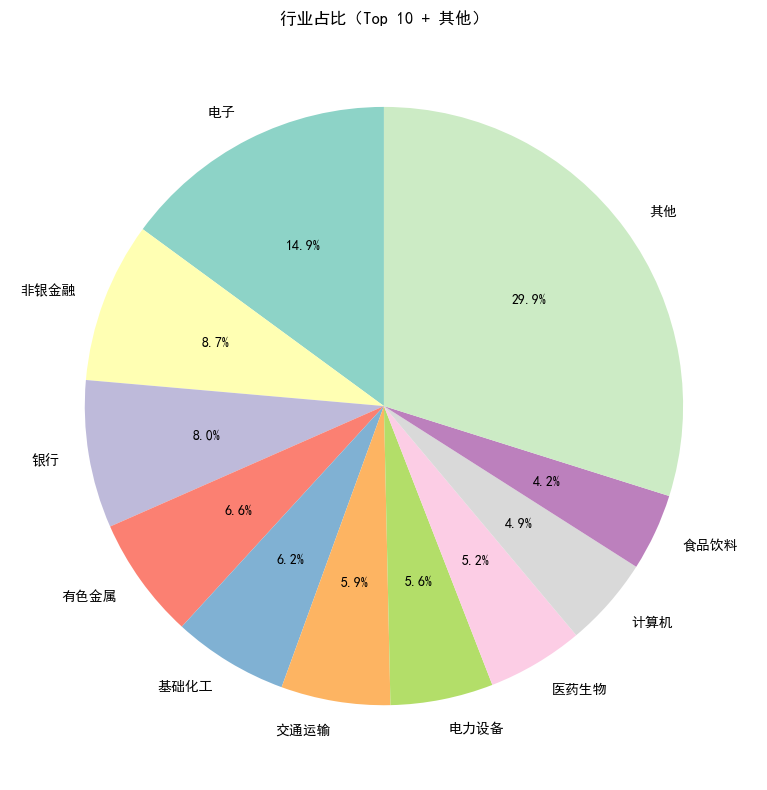


各行业平均日收益率（%）:
industry
医药生物    0.1459
电子      0.1338
计算机     0.1273
煤炭      0.0969
食品饮料    0.0912
电力设备    0.0908
国防军工    0.0855
家用电器    0.0853
农林牧渔    0.0843
基础化工    0.0792
商贸零售    0.0717
机械设备    0.0682
石油石化    0.0675
传媒      0.0667
汽车      0.0579
公用事业    0.0525
有色金属    0.0518
通信      0.0514
非银金融    0.0431
钢铁      0.0407
综合      0.0330
建筑材料    0.0218
交通运输    0.0202
建筑装饰    0.0198
银行      0.0159
纺织服饰    0.0124
房地产    -0.0089
社会服务   -0.0486
Name: pct_change, dtype: float64


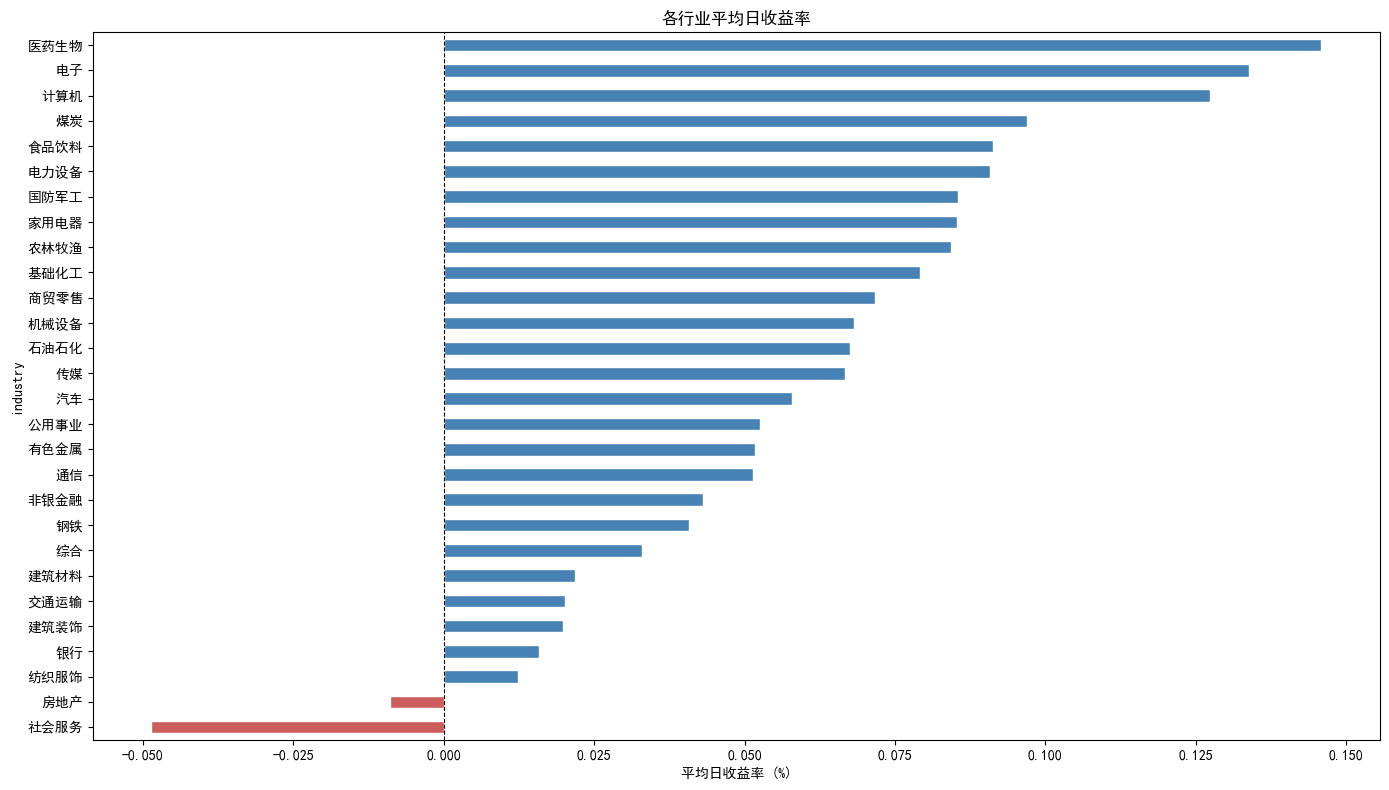

In [38]:
if industry is None:
    industry = load_if_exists(RAW_DIR / "industry_classification.parquet", "行业分类(原始)")

if industry is not None:
    print(f"\n列: {industry.columns.tolist()}")
    print(f"形状: {industry.shape}")
    print(f"\n前 10 行:")
    print(industry.head(10))

    # ----- 5.1 行业分布 -----
    if "industry" in industry.columns:
        industry_counts = industry["industry"].value_counts()
        print(f"\n行业数量: {industry_counts.shape[0]} 个")
        print(f"\n各行业股票数（按数量排序）:")
        print(industry_counts)

        # 画行业分布柱状图
        fig, ax = plt.subplots(figsize=(14, 8))
        industry_counts.sort_values().plot(kind="barh", ax=ax, color="steelblue", edgecolor="white")
        ax.set_title(f"行业分布（共 {industry_counts.shape[0]} 个行业，{industry.shape[0]} 只股票）")
        ax.set_xlabel("股票数")
        plt.tight_layout()
        plt.savefig(PROJECT_ROOT / "notebooks" / "industry_distribution.png", dpi=100, bbox_inches="tight")
        plt.show()

        # ----- 5.2 行业占比饼图（Top 10 + 其他） -----
        top_n = 10
        if len(industry_counts) > top_n:
            top_industries = industry_counts.head(top_n)
            other_count = industry_counts.iloc[top_n:].sum()
            pie_data = pd.concat([top_industries, pd.Series({"其他": other_count})])
        else:
            pie_data = industry_counts

        fig, ax = plt.subplots(figsize=(10, 8))
        ax.pie(pie_data.values, labels=pie_data.index, autopct="%1.1f%%",
               startangle=90, colors=plt.cm.Set3.colors)
        ax.set_title(f"行业占比（Top {top_n} + 其他）")
        plt.tight_layout()
        plt.savefig(PROJECT_ROOT / "notebooks" / "industry_pie.png", dpi=100, bbox_inches="tight")
        plt.show()

    # ----- 5.3 行业与收益/因子结合分析 -----
    if market_data is not None and "industry" in industry.columns:
        # 把行业映射到市场数据
        industry_map = industry.set_index("code")["industry"]
        market_with_industry = market_data.copy()
        market_with_industry["industry"] = market_with_industry.index.get_level_values("code").map(industry_map)

        # 各行业平均日收益
        if "pct_change" in market_with_industry.columns:
            industry_returns = market_with_industry.dropna(subset=["industry"]).groupby("industry")["pct_change"].mean()
            industry_returns = industry_returns.sort_values(ascending=False)

            print(f"\n各行业平均日收益率（%）:")
            print(industry_returns)

            fig, ax = plt.subplots(figsize=(14, 8))
            industry_returns.sort_values().plot(kind="barh", ax=ax,
                                                 color=industry_returns.sort_values().apply(
                                                     lambda x: "indianred" if x < 0 else "steelblue"),
                                                 edgecolor="white")
            ax.axvline(0, color="black", linestyle="--", linewidth=0.8)
            ax.set_title("各行业平均日收益率")
            ax.set_xlabel("平均日收益率 (%)")
            plt.tight_layout()
            plt.savefig(PROJECT_ROOT / "notebooks" / "industry_returns.png", dpi=100, bbox_inches="tight")
            plt.show()




6. 财务数据探索 financial_data.parquet


[OK] 加载 财务数据: shape=(13085, 12)

列: ['ts_code', 'ann_date', 'report_date', 'roe', 'roa', 'gross_margin', 'net_margin', 'debt_ratio', 'current_ratio', 'revenue_growth', 'code', 'publish_date']
形状: (13085, 12)

前 5 行:
     ts_code  ann_date report_date    roe    roa  gross_margin  net_margin  debt_ratio  current_ratio  revenue_growth    code publish_date
0  600118.SH  20240417  2023-12-31 2.2850 0.9820       11.8893      2.4631     39.3499         2.0190        -16.5143  600118   2024-04-29
1  600118.SH  20231031  2023-09-30 2.5545 1.2282       15.0881      5.9461     44.4000         1.8450        -30.5276  600118   2023-10-30
2  600118.SH  20230825  2023-06-30 2.2509 0.9920       15.9262      7.3006     44.0613         1.8570        -25.8625  600118   2023-08-29
3  600118.SH  20230428  2023-03-31 0.7451 0.3842       13.1803      4.9455     42.4673         1.9171         -4.7717  600118   2023-04-30
4  600118.SH  20230428  2023-03-31 0.7451 0.3842       13.1803      4.9455     42.4673   

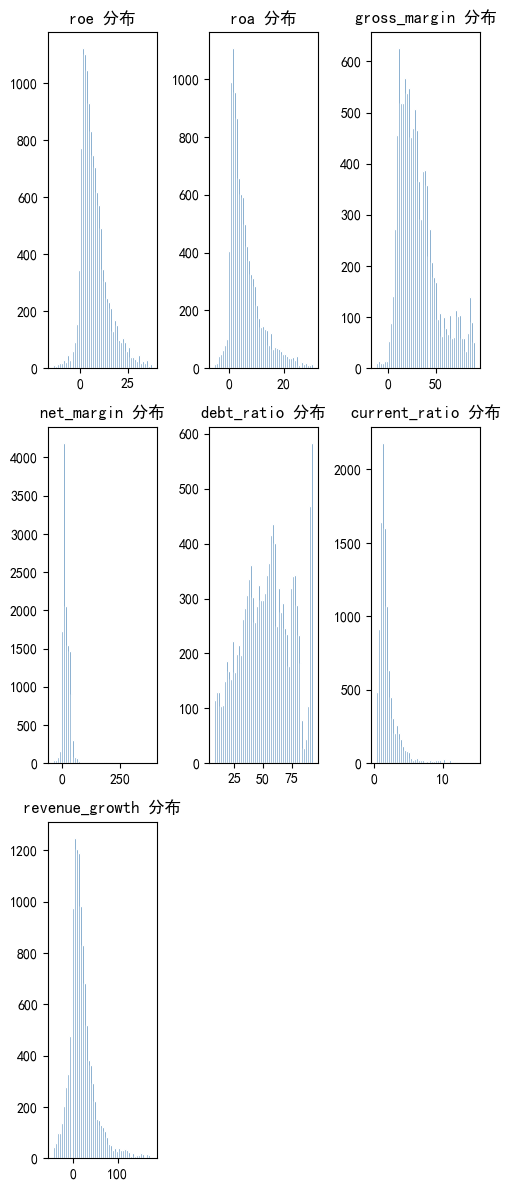

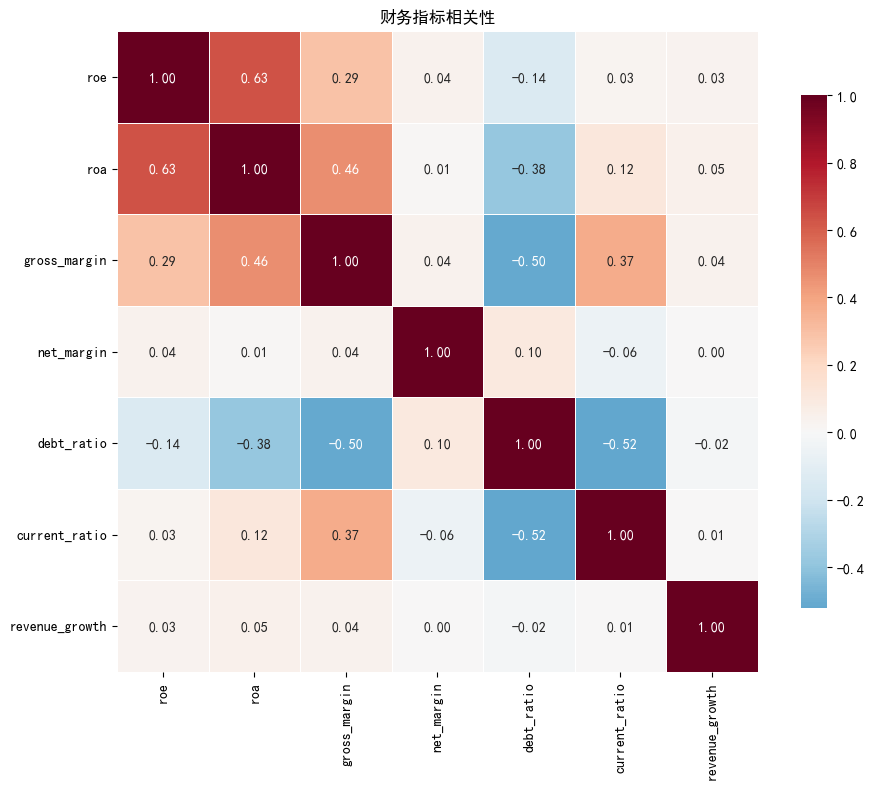


报告期范围: 2018-03-31 00:00:00 ~ 2023-12-31 00:00:00
发布日范围: 2018-04-30 00:00:00 ~ 2024-04-29 00:00:00

报告期数量: 24
股票数: 288


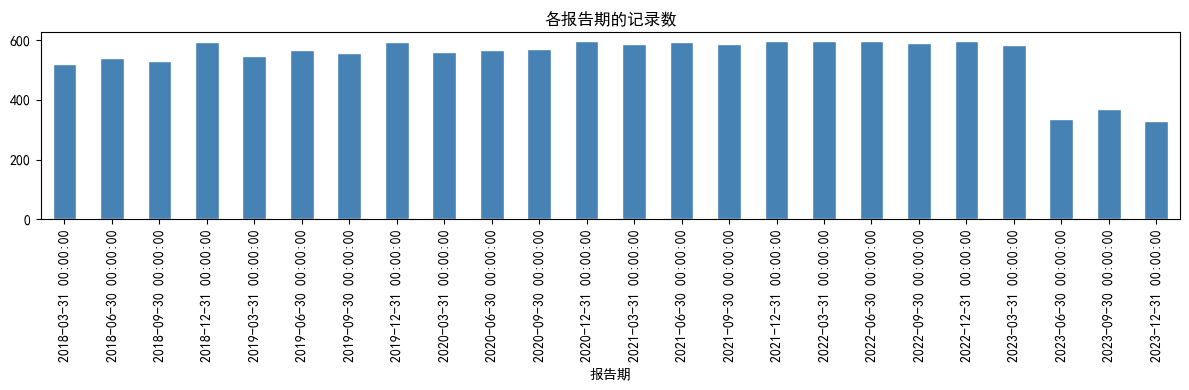


股票 600118 的财务数据:
   report_date publish_date    roe    roa  gross_margin  net_margin  debt_ratio  current_ratio  revenue_growth
44  2018-03-31   2018-04-30 1.0026 0.7468       14.6337      5.3092     37.2274         2.1368         13.6269
43  2018-03-31   2018-04-30 1.0026 0.7468       14.6337      5.3092     37.2274         2.1368         13.6269
41  2018-06-30   2018-08-29 3.1178 1.9274       13.6389      6.1250     43.3117         1.8889         19.8734
42  2018-06-30   2018-08-29 3.1178 1.9274       13.6389      6.1250     43.3117         1.8889         19.8734
40  2018-09-30   2018-10-30 4.6810 3.3128       14.3472      6.3184     47.0583         1.7644         13.4060
39  2018-09-30   2018-10-30 4.6810 3.3128       14.3472      6.3184     47.0583         1.7644         13.4060
38  2018-12-31   2019-04-30 6.7330 5.0323       13.6283      6.1859     36.3996         2.1794          2.6808
37  2018-12-31   2019-04-30 6.7330 5.0323       13.6283      6.1859     36.3996         2.1794

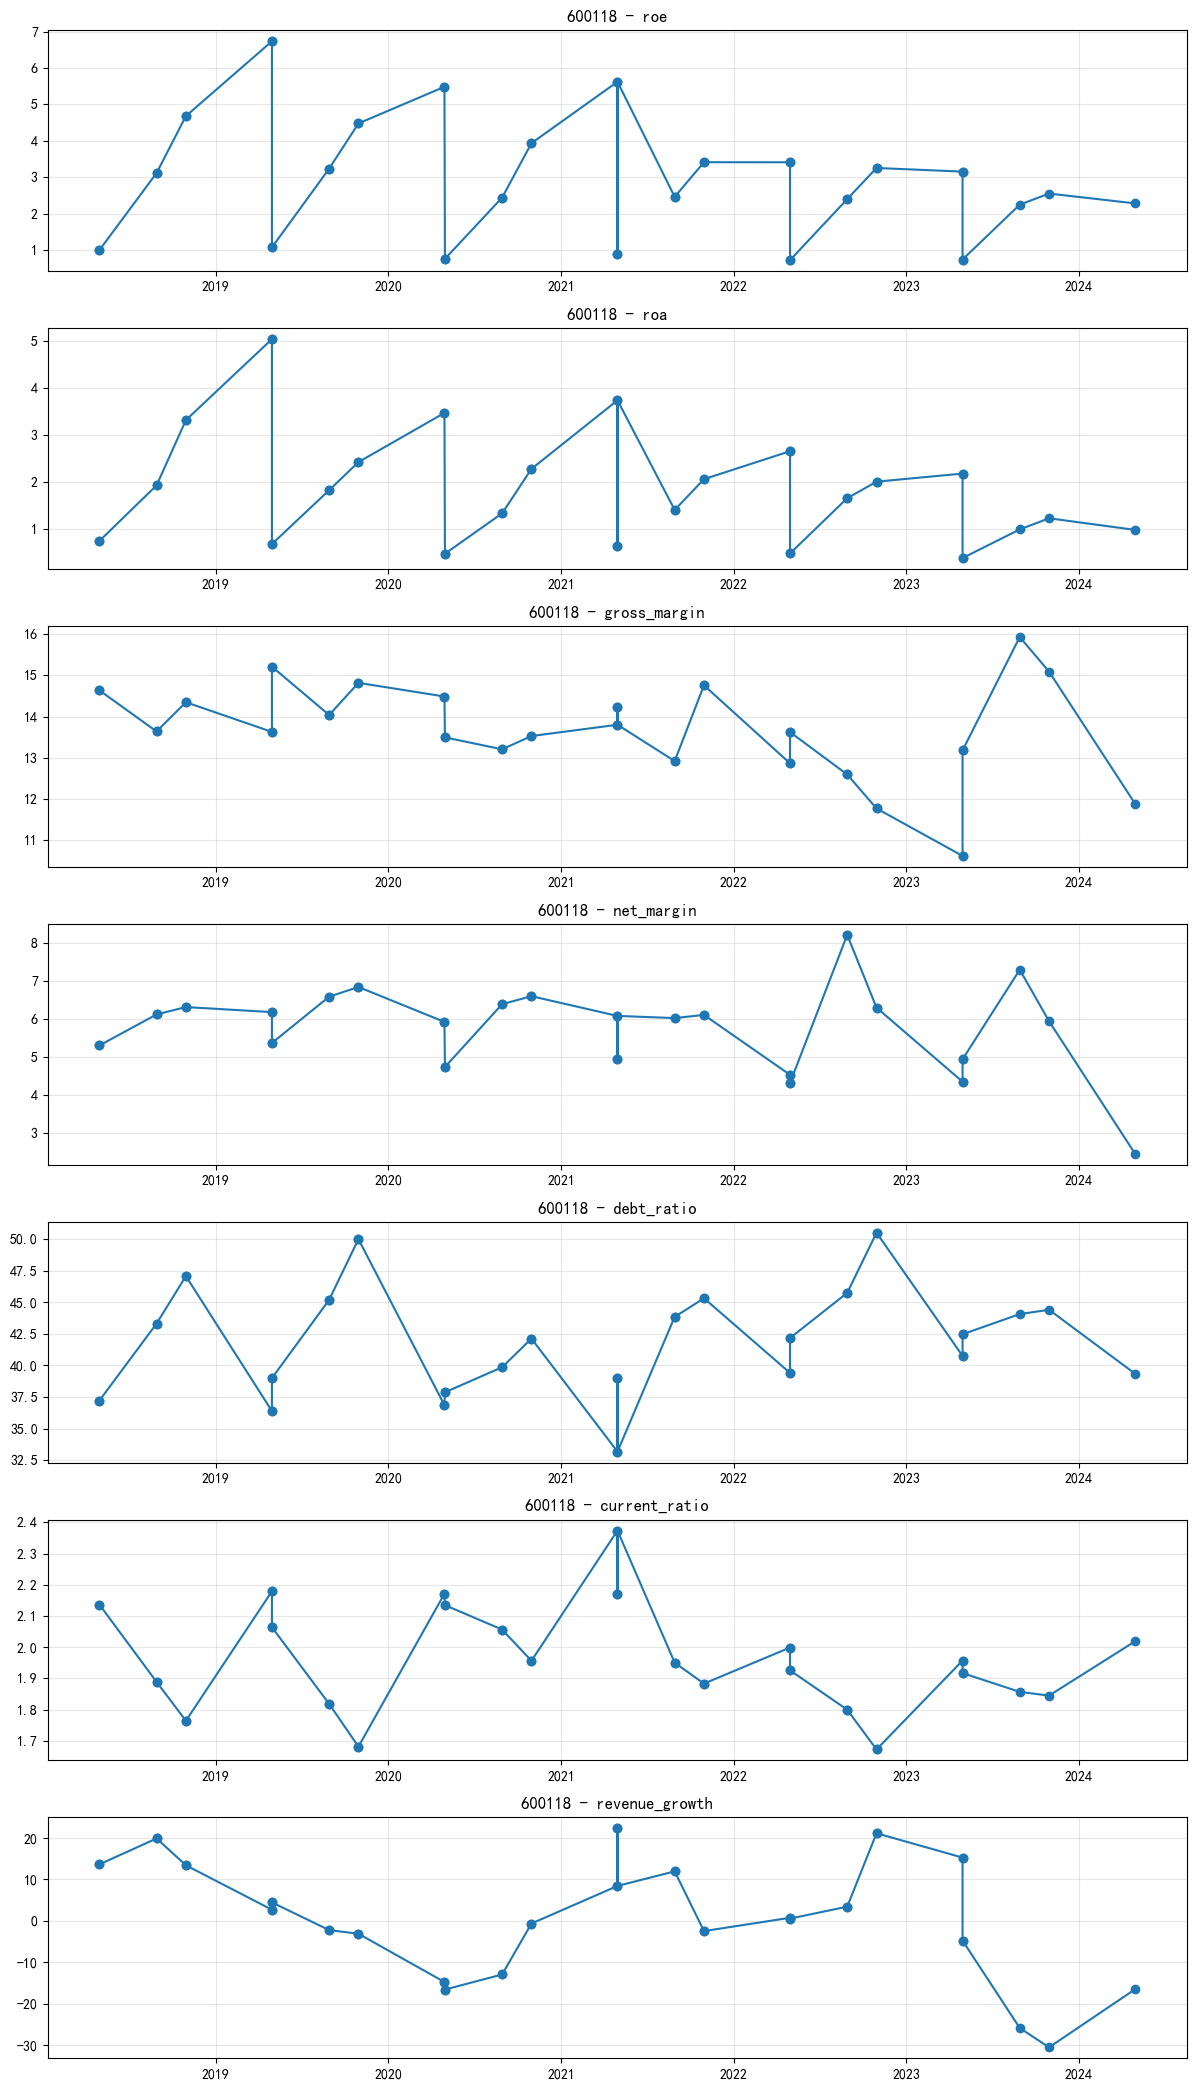

In [40]:
# ============================================================
# 6. 财务数据探索 financial_data.parquet
# ============================================================

financial = load_if_exists(PROC_DIR / "financial_data.parquet", "财务数据")
if financial is None:
    financial = load_if_exists(RAW_DIR / "financial_data.parquet", "财务数据(原始)")

if financial is not None:
    print(f"\n列: {financial.columns.tolist()}")
    print(f"形状: {financial.shape}")
    print(f"\n前 5 行:")
    print(financial.head())

    # ----- 6.1 描述性统计 -----
    quality_cols = [c for c in ["roe", "roa", "gross_margin", "net_margin",
                                 "debt_ratio", "current_ratio", "revenue_growth"]
                    if c in financial.columns]
    if quality_cols:
        print(f"\n财务指标描述性统计:")
        print(financial[quality_cols].describe().T)

        # ----- 6.2 各指标分布 -----
        n = len(quality_cols)
        fig, axes = plt.subplots((n + 2) // 3, 3, figsize=(5, 4 * ((n + 2) // 3)))
        axes = axes.flatten()
        for ax, col in zip(axes, quality_cols):
            data = financial[col].dropna()
            data = data[(data > data.quantile(0.01)) & (data < data.quantile(0.99))]
            ax.hist(data, bins=50, color="steelblue", edgecolor="white")
            ax.set_title(f"{col} 分布")
        for ax in axes[len(quality_cols):]:
            ax.axis("off")
        plt.tight_layout()
        plt.savefig(PROJECT_ROOT / "notebooks" / "financial_dist.png", dpi=100, bbox_inches="tight")
        plt.show()

        # ----- 6.3 财务指标相关性 -----
        corr = financial[quality_cols].corr()
        fig, ax = plt.subplots(figsize=(10, 8))
        sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0,
                    ax=ax, square=True, linewidths=0.5, cbar_kws={"shrink": 0.8})
        ax.set_title("财务指标相关性")
        plt.tight_layout()
        plt.savefig(PROJECT_ROOT / "notebooks" / "financial_corr.png", dpi=100, bbox_inches="tight")
        plt.show()

    # ----- 6.4 报告期与发布日 -----
    if "report_date" in financial.columns and "publish_date" in financial.columns:
        print(f"\n报告期范围: {financial['report_date'].min()} ~ {financial['report_date'].max()}")
        print(f"发布日范围: {financial['publish_date'].min()} ~ {financial['publish_date'].max()}")
        print(f"\n报告期数量: {financial['report_date'].nunique()}")
        print(f"股票数: {financial['code'].nunique() if 'code' in financial.columns else 'N/A'}")

        # 报告期分布
        report_counts = financial["report_date"].value_counts().sort_index()
        fig, ax = plt.subplots(figsize=(14, 4))
        report_counts.plot(kind="bar", ax=ax, color="steelblue", edgecolor="white")
        ax.set_title("各报告期的记录数")
        ax.set_xlabel("报告期")
        plt.tight_layout()
        plt.savefig(PROJECT_ROOT / "notebooks" / "financial_report_dates.png", dpi=100, bbox_inches="tight")
        plt.show()

    # ----- 6.5 一只股票的财务时序 -----
    if "code" in financial.columns and quality_cols:
        sample_code = financial["code"].iloc[0]
        one_stock_fin = financial[financial["code"] == sample_code].sort_values("publish_date")
        print(f"\n股票 {sample_code} 的财务数据:")
        print(one_stock_fin[["report_date", "publish_date"] + quality_cols].head(10))

        fig, axes = plt.subplots(len(quality_cols), 1, figsize=(14, 3 * len(quality_cols)))
        if len(quality_cols) == 1:
            axes = [axes]
        for ax, col in zip(axes, quality_cols):
            ax.plot(one_stock_fin["publish_date"], one_stock_fin[col], marker="o")
            ax.set_title(f"{sample_code} - {col}")
            ax.grid(True, alpha=0.3)
        plt.tight_layout()
        plt.savefig(PROJECT_ROOT / "notebooks" / "financial_timeseries.png", dpi=100, bbox_inches="tight")
        plt.show()


7. 清洗后的市场数据 market_data.parquet


In [27]:
market_data = load_if_exists(PROC_DIR / "market_data.parquet", "清洗后市场数据")

[OK] 加载 清洗后市场数据: shape=(373806, 14)


In [28]:
if market_data is not None:
    print(f"\n列: {market_data.columns.tolist()}")
    print(f"日期范围: {market_data.index.get_level_values('date').min()} ~ "
          f"{market_data.index.get_level_values('date').max()}")
    print(f"股票数: {market_data.index.get_level_values('code').nunique()}")
    print(f"\n缺失率:")
    print(market_data.isna().mean().sort_values(ascending=False))


列: ['open', 'high', 'low', 'close', 'pre_close', 'volume', 'amount', 'pct_change', 'pe_ttm', 'pb', 'ps_ttm', 'total_mv', 'dv_ratio', 'turnover_rate']
日期范围: 2018-01-02 00:00:00 ~ 2023-12-29 00:00:00
股票数: 285

缺失率:
dv_ratio        0.0522
pe_ttm          0.0444
pb              0.0011
open            0.0000
high            0.0000
low             0.0000
close           0.0000
pre_close       0.0000
volume          0.0000
amount          0.0000
pct_change      0.0000
ps_ttm          0.0000
total_mv        0.0000
turnover_rate   0.0000
dtype: float64



8. 因子数据 factors.parquet（原始因子）


In [32]:
factors = load_if_exists(PROC_DIR / "factors.parquet", "原始因子")

[OK] 加载 原始因子: shape=(373806, 26)


In [33]:
if factors is not None:
    print(f"\n因子列表 ({len(factors.columns)} 个):")
    for i, col in enumerate(factors.columns, 1):
        print(f"  {i:2d}. {col}")

    print(f"\n前 5 行:")
    print(factors.head())

    print(f"\n各因子缺失率:")
    print(factors.isna().mean().sort_values(ascending=False))

    print(f"\n各因子描述性统计:")
    print(factors.describe().T)


因子列表 (26 个):
   1. mom_5d
   2. mom_10d
   3. mom_20d
   4. mom_60d
   5. mom_20d_std
   6. high_52w_dist
   7. rev_1d
   8. rev_5d
   9. vol_20d
  10. atr_14d
  11. down_vol_20d
  12. turnover_rate
  13. volume_ratio
  14. vol_price_corr
  15. ep
  16. bp
  17. sp
  18. dv_ttm
  19. ln_market_cap
  20. roe
  21. roa
  22. gross_margin
  23. net_margin
  24. debt_ratio
  25. current_ratio
  26. revenue_growth

前 5 行:
                   mom_5d  mom_10d  mom_20d  mom_60d  mom_20d_std  high_52w_dist  rev_1d  rev_5d  vol_20d  atr_14d  down_vol_20d  turnover_rate  volume_ratio  vol_price_corr     ep     bp     sp  \
date       code                                                                                                                                                                                      
2018-01-02 000001     NaN      NaN      NaN      NaN          NaN            NaN     NaN     NaN      NaN      NaN           NaN         1.2304           NaN             NaN 0.0979 0


9. 预处理后的因子 factors_processed.parquet


In [34]:
factors_processed = load_if_exists(PROC_DIR / "factors_processed.parquet", "预处理后因子")

[OK] 加载 预处理后因子: shape=(373806, 26)



前 5 行:
                   mom_5d  mom_10d  mom_20d  mom_60d  mom_20d_std  high_52w_dist  rev_1d  rev_5d  vol_20d  atr_14d  down_vol_20d  turnover_rate  volume_ratio  vol_price_corr     ep      bp      sp  \
date       code                                                                                                                                                                                        
2018-01-02 000001     NaN      NaN      NaN      NaN          NaN            NaN     NaN     NaN      NaN      NaN           NaN         0.5882           NaN             NaN 0.0329 -0.4754  0.1934   
           000002     NaN      NaN      NaN      NaN          NaN            NaN     NaN     NaN      NaN      NaN           NaN        -0.4414           NaN             NaN 0.2274 -0.5270  0.2785   
           000063     NaN      NaN      NaN      NaN          NaN            NaN     NaN     NaN      NaN      NaN           NaN         0.5685           NaN             NaN    NaN -0.3562  0.

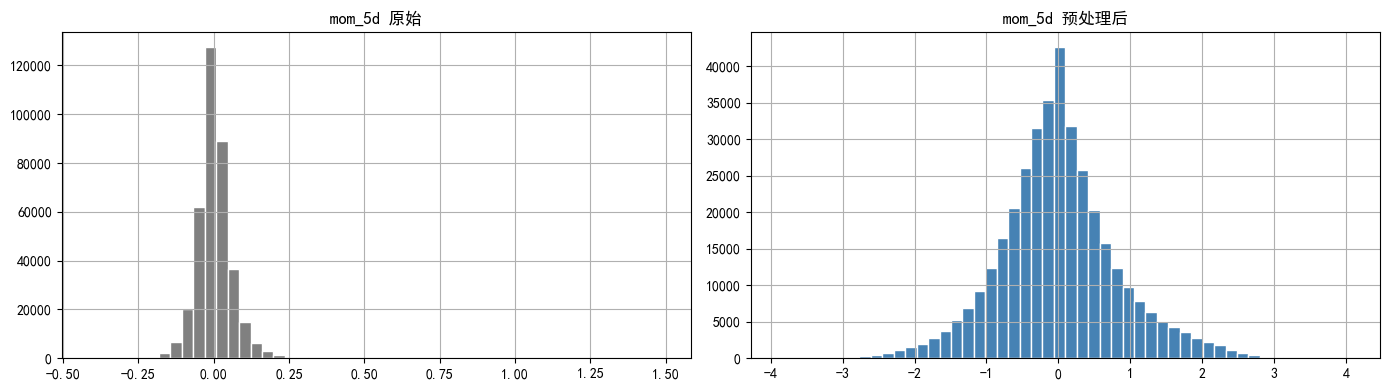

In [35]:
if factors_processed is not None:
    print(f"\n前 5 行:")
    print(factors_processed.head())

    print(f"\n各因子描述性统计（标准化后应接近 mean=0, std=1）:")
    print(factors_processed.describe().T[["mean", "std", "min", "max"]])

    # ----- 对比原始 vs 预处理 -----
    if factors is not None:
        common_cols = factors.columns.intersection(factors_processed.columns)
        if len(common_cols) > 0:
            col = common_cols[0]
            fig, axes = plt.subplots(1, 2, figsize=(14, 4))
            factors[col].dropna().hist(bins=50, ax=axes[0], color="gray", edgecolor="white")
            axes[0].set_title(f"{col} 原始")
            factors_processed[col].dropna().hist(bins=50, ax=axes[1], color="steelblue", edgecolor="white")
            axes[1].set_title(f"{col} 预处理后")
            plt.tight_layout()
            plt.savefig(PROJECT_ROOT / "notebooks" / "factor_before_after.png", dpi=100, bbox_inches="tight")
            plt.show()


10. 标签数据 labels.parquet


In [41]:
labels = load_if_exists(PROC_DIR / "labels.parquet", "标签")

[OK] 加载 标签: shape=(367251, 2)



列: ['label', 'forward_return']

前 5 行:
                    label  forward_return
date       code                          
2018-01-02 000001 -0.2037         -0.0036
           000002  1.0800          0.1167
           000063 -1.5470         -0.1296
           000157 -0.2820         -0.0110
           000166  0.0335          0.0186

描述性统计:
            label  forward_return
count 367251.0000     367251.0000
mean      -0.0000          0.0112
std        0.9980          0.1283
min       -4.9127         -0.5277
25%       -0.6021         -0.0598
50%       -0.1296         -0.0028
75%        0.4696          0.0630
max       15.1823          5.7317


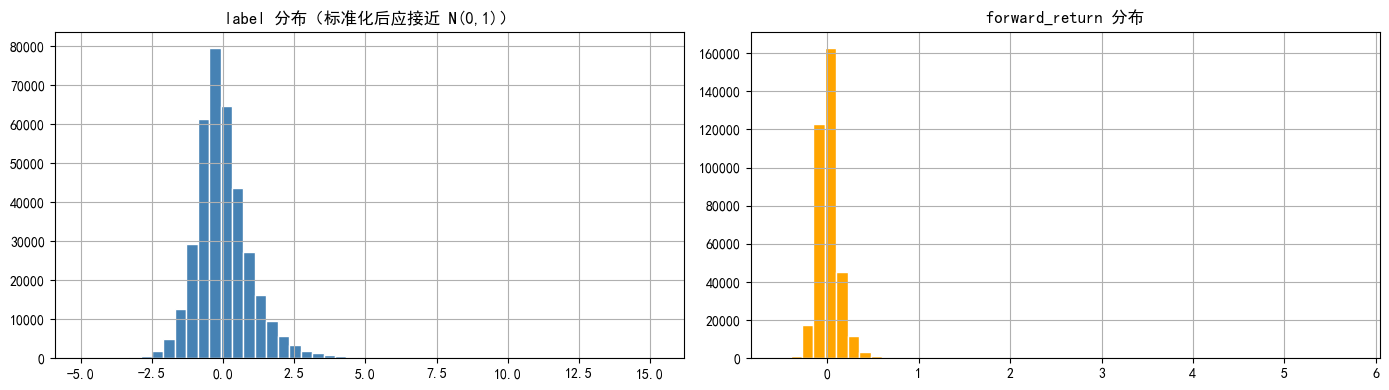

In [42]:
if labels is not None:
    print(f"\n列: {labels.columns.tolist()}")
    print(f"\n前 5 行:")
    print(labels.head())

    print(f"\n描述性统计:")
    print(labels.describe())

    # 标签分布
    fig, axes = plt.subplots(1, 2, figsize=(14, 4))
    labels["label"].dropna().hist(bins=50, ax=axes[0], color="steelblue", edgecolor="white")
    axes[0].set_title("label 分布（标准化后应接近 N(0,1)）")
    labels["forward_return"].dropna().hist(bins=50, ax=axes[1], color="orange", edgecolor="white")
    axes[1].set_title("forward_return 分布")
    plt.tight_layout()
    plt.savefig(PROJECT_ROOT / "notebooks" / "label_dist.png", dpi=100, bbox_inches="tight")
    plt.show()


11. 模型预测 predictions.parquet


预测文件 (4 个):
  lightgbm_predictions.parquet
  linear_regression_predictions.parquet
  random_forest_predictions.parquet
  xgboost_predictions.parquet

lightgbm_predictions.parquet 前 5 行:
                     pred   label  window_id
date       code                             
2021-03-16 000002 -0.0941 -1.3120          0
           000063  0.0475 -0.1567          0
           000157  0.2336 -0.1098          0
           000301  0.0087  1.5142          0
           000333  0.0151 -0.2962          0

列: ['pred', 'label', 'window_id']
形状: (132231, 3)
<bound method Index.unique of DatetimeIndex(['2021-03-16', '2021-03-16', '2021-03-16', '2021-03-16', '2021-03-16', '2021-03-16', '2021-03-16', '2021-03-16', '2021-03-16', '2021-03-16',
               ...
               '2023-12-01', '2023-12-01', '2023-12-01', '2023-12-01', '2023-12-01', '2023-12-01', '2023-12-01', '2023-12-01', '2023-12-01', '2023-12-01'],
              dtype='datetime64[ns]', name='date', length=132231, freq=None)>


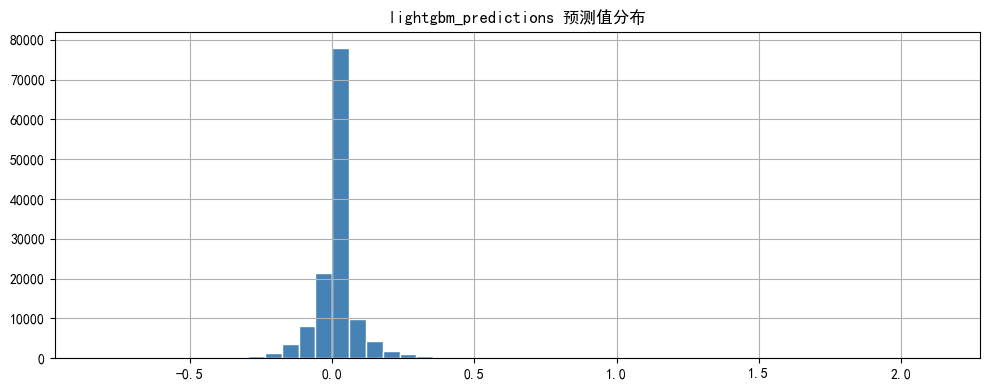

In [45]:
pred_dir = OUT_DIR / "predictions"
if pred_dir.exists():
    pred_files = sorted(pred_dir.glob("*_predictions.parquet"))
    print(f"预测文件 ({len(pred_files)} 个):")
    for f in pred_files:
        print(f"  {f.name}")

    # 加载第一个模型的预测
    if pred_files:
        pred = pd.read_parquet(pred_files[0])
        print(f"\n{pred_files[0].name} 前 5 行:")
        print(pred.head())
        print(f"\n列: {pred.columns.tolist()}")
        print(f"形状: {pred.shape}")
        print(pred.index.get_level_values("date").unique)

        # 预测值分布
        if "pred" in pred.columns:
            fig, ax = plt.subplots(figsize=(10, 4))
            pred["pred"].dropna().hist(bins=50, ax=ax, color="steelblue", edgecolor="white")
            ax.set_title(f"{pred_files[0].stem} 预测值分布")
            plt.tight_layout()
            plt.savefig(PROJECT_ROOT / "notebooks" / "pred_dist.png", dpi=100, bbox_inches="tight")
            plt.show()


12. 回测结果 backtest_*.parquet


回测结果文件 (4 个):
  backtest_lightgbm.parquet
  backtest_linear_regression.parquet
  backtest_random_forest.parquet
  backtest_xgboost.parquet

backtest_lightgbm.parquet 前 5 行:
            group_1  group_2  group_3  group_4  group_5  long_only_top  long_only_nav
2021-03-16  -0.0090  -0.0049  -0.0130   0.0112   0.0139         0.0139         1.0139
2021-04-14   0.0346   0.0325   0.0381   0.0523   0.0762         0.0762         1.0912
2021-05-17   0.0079   0.0028   0.0378   0.0954   0.0955         0.0955         1.1953
2021-06-15   0.0010   0.0109   0.0239   0.0647   0.1075         0.1075         1.3238
2021-07-13   0.0035   0.0234   0.0383   0.0128   0.0508         0.0508         1.3911

backtest_lightgbm.parquet 形状: (34, 7)
列: ['group_1', 'group_2', 'group_3', 'group_4', 'group_5', 'long_only_top', 'long_only_nav']


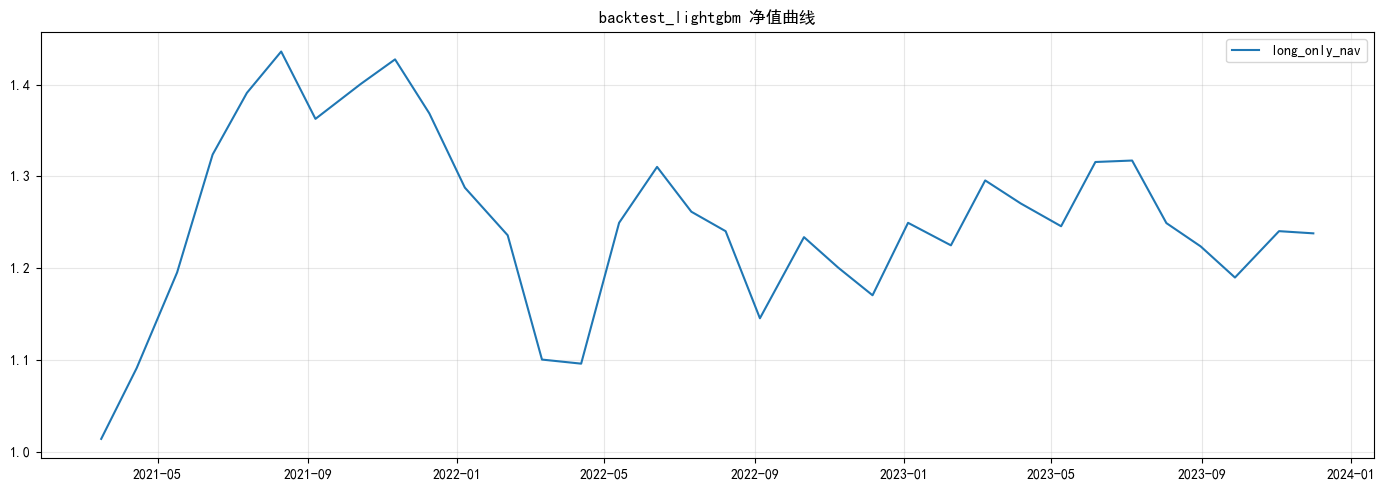

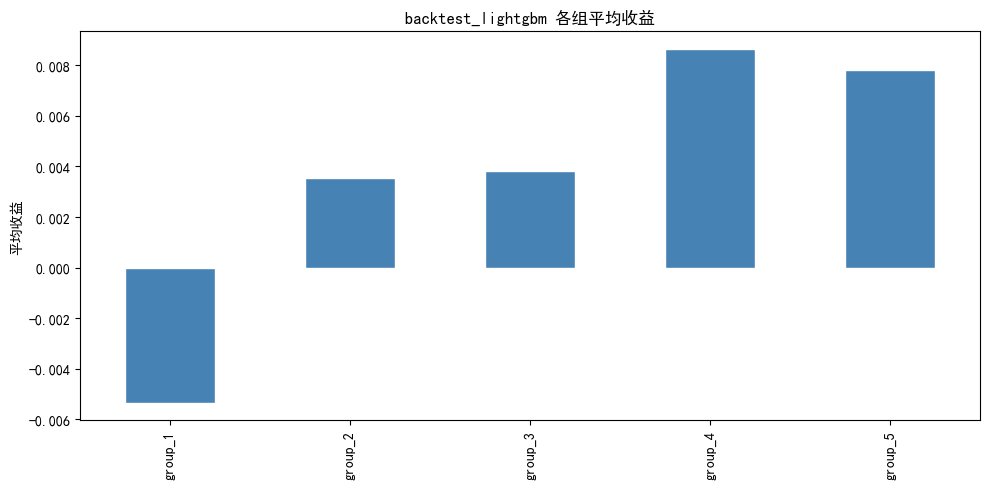

In [47]:
bt_files = sorted(OUT_DIR.glob("backtest_*.parquet"))
if bt_files:
    print(f"回测结果文件 ({len(bt_files)} 个):")
    for f in bt_files:
        print(f"  {f.name}")

    # 加载第一个
    bt = pd.read_parquet(bt_files[0])
    print(f"\n{bt_files[0].name} 前 5 行:")
    print(bt.head())
    print(f"\n{bt_files[0].name} 形状: {bt.shape}")
    print(f"列: {bt.columns.tolist()}")

    # 画净值曲线
    nav_cols = [c for c in bt.columns if "nav" in c]
    if nav_cols:
        fig, ax = plt.subplots(figsize=(14, 5))
        for col in nav_cols:
            ax.plot(bt.index, bt[col], label=col)
        ax.set_title(f"{bt_files[0].stem} 净值曲线")
        ax.legend()
        ax.grid(True, alpha=0.3)
        plt.tight_layout()
        plt.savefig(PROJECT_ROOT / "notebooks" / "nav_curve.png", dpi=100, bbox_inches="tight")
        plt.show()

    # 分组收益
    group_cols = [c for c in bt.columns if c.startswith("group_")]
    if group_cols:
        fig, ax = plt.subplots(figsize=(10, 5))
        bt[group_cols].mean().plot(kind="bar", ax=ax, color="steelblue", edgecolor="white")
        ax.set_title(f"{bt_files[0].stem} 各组平均收益")
        ax.set_ylabel("平均收益")
        plt.tight_layout()
        plt.savefig(PROJECT_ROOT / "notebooks" / "group_returns.png", dpi=100, bbox_inches="tight")
        plt.show()


13. 评估汇总 evaluation_summary.parquet / csv


模型评估汇总:
                   ic_mean  ic_std    icir  ic_positive_ratio  annual_return_top  annual_vol_top  sharpe_top  max_drawdown_top  calmar_top  monotonic  long_short_diff
model_name                                                                                                                                                            
lightgbm            0.0354  0.1408  0.2514             0.6581             3.8653          0.8979      4.2771           -0.2369     16.3156      False           0.0132
linear_regression  -0.0118  0.1449 -0.0815             0.4720             2.8987          0.9246      3.1080           -0.2643     10.9680      False           0.0035
random_forest       0.0136  0.1360  0.1000             0.5749             1.6772          0.9068      1.8221           -0.2326      7.2115      False           0.0060
xgboost             0.0130  0.1062  0.1226             0.5477             2.6057          0.8164      3.1612           -0.2143     12.1562      False        

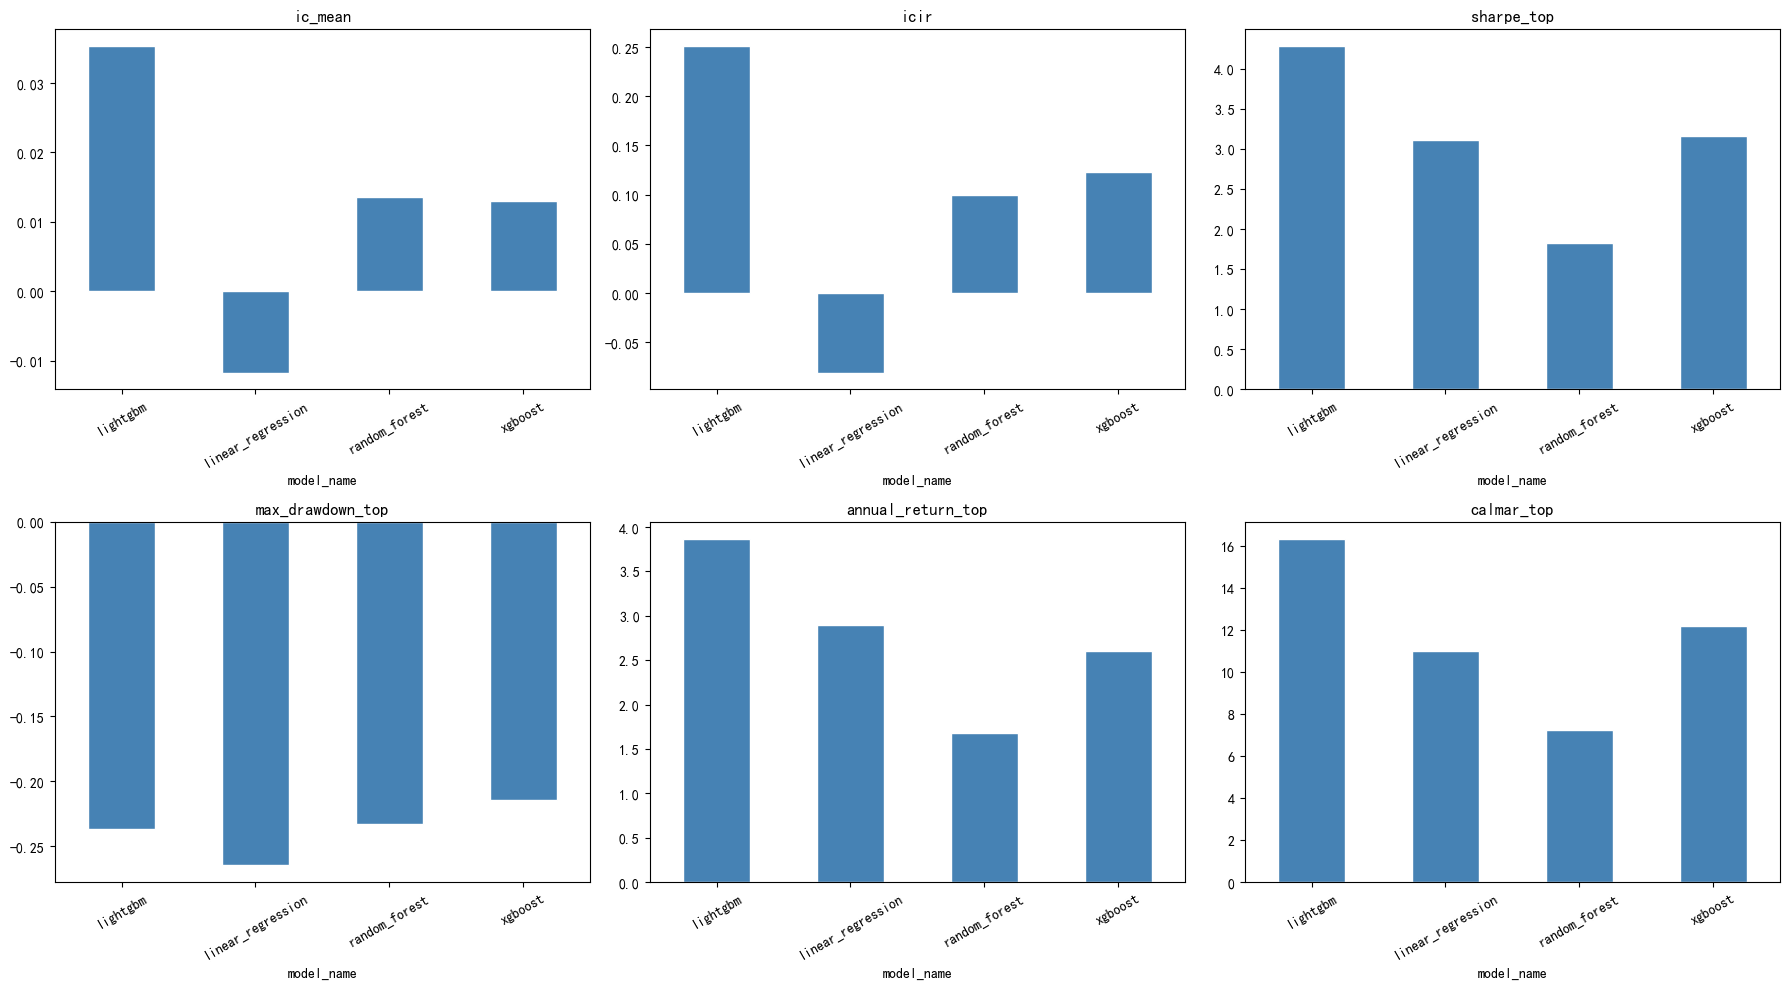

In [48]:
eval_file = OUT_DIR / "evaluation_summary.parquet"
if eval_file.exists():
    eval_summary = pd.read_parquet(eval_file)
    print("模型评估汇总:")
    print(eval_summary)

    # 关键指标对比
    key_cols = [c for c in ["ic_mean", "icir", "sharpe_top", "max_drawdown_top",
                            "annual_return_top", "calmar_top"] if c in eval_summary.columns]
    if key_cols:
        fig, axes = plt.subplots(2, 3, figsize=(18, 10))
        axes = axes.flatten()
        for ax, col in zip(axes, key_cols):
            eval_summary[col].plot(kind="bar", ax=ax, color="steelblue", edgecolor="white")
            ax.set_title(col)
            ax.tick_params(axis="x", rotation=30)
        plt.tight_layout()
        plt.savefig(PROJECT_ROOT / "notebooks" / "model_comparison.png", dpi=100, bbox_inches="tight")
        plt.show()


14. 交互式探索：自己动手


你可以在这里改代码，做自己的探索：

In [ ]:
# 14.1 看某只股票某段时期的因子
if factors_processed is not None:
    code = factors_processed.index.get_level_values("code").unique()[0]
    one_stock_factors = factors_processed.xs(code, level="code")
    print(f"\n股票 {code} 的因子前 5 行:")
    print(one_stock_factors.head())

    # 画几个因子的时序
    factor_cols = [c for c in ["mom_20d", "vol_20d", "ep", "turnover_rate"]
                   if c in one_stock_factors.columns]
    if factor_cols:
        fig, axes = plt.subplots(len(factor_cols), 1, figsize=(14, 3*len(factor_cols)), sharex=True)
        if len(factor_cols) == 1:
            axes = [axes]
        for ax, col in zip(axes, factor_cols):
            ax.plot(one_stock_factors.index, one_stock_factors[col])
            ax.set_title(f"{code} - {col}")
            ax.grid(True, alpha=0.3)
        plt.tight_layout()
        plt.savefig(PROJECT_ROOT / "notebooks" / "stock_factors.png", dpi=100, bbox_inches="tight")
        plt.show()

In [ ]:
# 14.2 因子相关性
if factors_processed is not None:
    corr = factors_processed.corr()
    fig, ax = plt.subplots(figsize=(14, 14))
    sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0,
                ax=ax, square=True, linewidths=0.5, cbar_kws={"shrink": 0.8})
    ax.set_title("因子相关性矩阵")
    plt.tight_layout()
    plt.savefig(PROJECT_ROOT / "notebooks" / "factor_corr.png", dpi=100, bbox_inches="tight")
    plt.show()

In [ ]:
# 14.3 单因子 IC 分析
if factors_processed is not None and labels is not None:
    merged = factors_processed.join(labels[["label"]], how="inner")

    from scipy.stats import spearmanr

    ic_results = {}
    for col in factors_processed.columns:
        ic_series = merged.groupby(level="date").apply(
            lambda g: spearmanr(g[col], g["label"])[0] if len(g) > 10 else np.nan
        )
        ic_results[col] = {
            "IC均值": ic_series.mean(),
            "IC标准差": ic_series.std(),
            "ICIR": ic_series.mean() / ic_series.std() if ic_series.std() > 0 else 0,
            "IC>0占比": (ic_series > 0).mean(),
        }

    ic_df = pd.DataFrame(ic_results).T.sort_values("IC均值", ascending=False)
    print("\n单因子 IC 分析:")
    print(ic_df)

    # 画 IC 柱状图
    fig, ax = plt.subplots(figsize=(14, 6))
    ic_df["IC均值"].plot(kind="bar", ax=ax, color="steelblue", edgecolor="white")
    ax.axhline(0, color="red", linestyle="--", linewidth=0.8)
    ax.set_title("各因子 IC 均值")
    ax.set_ylabel("IC")
    plt.tight_layout()
    plt.savefig(PROJECT_ROOT / "notebooks" / "factor_ic.png", dpi=100, bbox_inches="tight")
    plt.show()

In [ ]:
# 14.4 看某天的横截面
if factors_processed is not None:
    sample_date = factors_processed.index.get_level_values("date").unique()[100]
    cross = factors_processed.xs(sample_date, level="date")
    print(f"\n{sample_date} 因子横截面（前 5 行）:")
    print(cross.head())

    # 因子横截面分布
    n_cols = min(6, len(cross.columns))
    fig, axes = plt.subplots(2, 3, figsize=(5, 8))
    axes = axes.flatten()
    for ax, col in zip(axes, cross.columns[:n_cols]):
        cross[col].dropna().hist(bins=30, ax=ax, color="steelblue", edgecolor="white")
        ax.set_title(f"{col} 横截面分布")
    plt.tight_layout()
    plt.savefig(PROJECT_ROOT / "notebooks" / "cross_section_factors.png", dpi=100, bbox_inches="tight")
    plt.show()


15. 数据质量检查清单


In [ ]:
print("\n" + "="*60)
print("数据质量检查")
print("="*60)

In [ ]:
def check_data(df, name):
    if df is None:
        print(f"\n[{name}] 未加载")
        return
    print(f"\n[{name}]")
    print(f"  形状: {df.shape}")
    print(f"  日期范围: {df.index.get_level_values('date').min()} ~ "
          f"{df.index.get_level_values('date').max()}" if "date" in df.index.names else "")
    print(f"  股票数: {df.index.get_level_values('code').nunique()}"
          if "code" in df.index.names else "")
    print(f"  缺失率 > 10% 的列:")
    missing = df.isna().mean()
    high_missing = missing[missing > 0.1].sort_values(ascending=False)
    if len(high_missing) > 0:
        for col, ratio in high_missing.items():
            print(f"    {col}: {ratio:.2%}")
    else:
        print("    无")
    print(f"  重复索引数: {df.index.duplicated().sum()}")

In [ ]:
check_data(daily_prices, "daily_prices")
check_data(valuation, "valuation")
check_data(market_data, "market_data")
check_data(factors, "factors")
check_data(factors_processed, "factors_processed")
check_data(labels, "labels")


16. 保存探索记录（可选）


In [ ]:
# 把关键统计导出为 CSV，方便查看
notebook_dir = PROJECT_ROOT / "notebooks"
notebook_dir.mkdir(exist_ok=True)

In [ ]:
if factors_processed is not None:
    factors_processed.describe().T.to_csv(notebook_dir / "factors_processed_stats.csv")
    print(f"\n因子统计已保存: {notebook_dir / 'factors_processed_stats.csv'}")

In [ ]:
if labels is not None:
    labels.describe().to_csv(notebook_dir / "labels_stats.csv")
    print(f"标签统计已保存: {notebook_dir / 'labels_stats.csv'}")

In [ ]:
print("\n" + "="*60)
print("探索完成！图表保存在:", notebook_dir)
print("="*60)